In [1]:
# FORMAT FOR TIME BASED EDA
# QUESTION
### OBJECTIVE
### CODE
### VISUALISATION
### OBSERVATION
### INSIGHTS
# GOING TO USE AVERAGE HOURLY RIDERSHIP = MEAN OF TOTAL RIDERSHIP FOR EACH HOUR
# creating reusable variables

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# plot settings
plt.style.use("default")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 2)

df=pd.read_csv("/Users/shivaya/Desktop/Research/DelhiMetroResearch/DataProcessed/metro_master.csv")


In [3]:
print(df.shape)
df.head(5)
df.sample(5)

(1872465, 9)


,businessday,linename,sitename,station name,station code,hour,count,month,direction
34828,2024-09-22,LINE02,AIIMS,Aiims,AIIM,8,555,September,Entry
1750780,2025-02-12,RMGL,Moulsari Avenue-RMGL,Moulsari Avenue,Moulsari Avenue,7,53,February,Exit
1269375,2025-01-05,LINE09,NazafGarh,Najafgarh,NFGH,5,0,January,Entry
1260728,2025-01-01,LINE01,Dilshad Garden,Dilshad Garden,DSG,4,0,January,Entry
140428,2024-09-01,LINE04,Anand Vihar ISBT,Anand Vihar Isbt,AVIT,23,261,September,Entry


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1872465 entries, 0 to 1872464
Data columns (total 9 columns):
 #   Column        Dtype
---  ------        -----
 0   businessday   str  
 1   linename      str  
 2   sitename      str  
 3   station name  str  
 4   station code  str  
 5   hour          int64
 6   count         int64
 7   month         str  
 8   direction     str  
dtypes: int64(2), str(7)
memory usage: 232.3 MB


In [5]:
df.columns.tolist()

['businessday',
 'linename',
 'sitename',
 'station name',
 'station code',
 'hour',
 'count',
 'month',
 'direction']

In [6]:
df.info()
df["direction"].value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 1872465 entries, 0 to 1872464
Data columns (total 9 columns):
 #   Column        Dtype
---  ------        -----
 0   businessday   str  
 1   linename      str  
 2   sitename      str  
 3   station name  str  
 4   station code  str  
 5   hour          int64
 6   count         int64
 7   month         str  
 8   direction     str  
dtypes: int64(2), str(7)
memory usage: 232.3 MB


direction
Entry    936243
Exit     936222
Name: count, dtype: int64

In [7]:
# Check missing values in columns required for time-based EDA
required_columns = [
    "businessday",
    "month",
    "hour",
    "direction",
    "count"
]

df[required_columns].isnull().sum()

businessday    0
month          0
hour           0
direction      0
count          0
dtype: int64

In [8]:
missing = pd.DataFrame({
    "Missing Values": df[required_columns].isnull().sum(),
    "Percentage (%)": (
        df[required_columns].isnull().mean() * 100
    ).round(2)
})

missing

,Missing Values,Percentage (%)
businessday,0,0.0
month,0,0.0
hour,0,0.0
direction,0,0.0
count,0,0.0


In [9]:
daily_hourly = (
    df.groupby(
        ["businessday", "month", "hour", "direction"],
        as_index=False 
    )["count"].sum()
)

In [10]:
daily_hourly.head()
daily_hourly.shape

(7602, 5)

In [11]:
print(df["month"].unique())

<ArrowStringArray>
['September', 'October', 'November', 'December', 'January', 'February']
Length: 6, dtype: str


In [12]:
daily_hourly.head(10)

,businessday,month,hour,direction,count
0,2024-09-01,September,0,Entry,56
1,2024-09-01,September,0,Exit,4456
2,2024-09-01,September,4,Entry,1
3,2024-09-01,September,4,Exit,0
4,2024-09-01,September,5,Entry,10655
5,2024-09-01,September,5,Exit,393
6,2024-09-01,September,6,Entry,42633
7,2024-09-01,September,6,Exit,14199
8,2024-09-01,September,7,Entry,70072
9,2024-09-01,September,7,Exit,50411


In [13]:
daily_hourly.describe()

,hour,count
count,7602.00,7602.00
mean,12.86,141915.52
std,6.32,99058.04
min,0.00,0.00
25%,8.00,46126.75
50%,13.00,159450.50
75%,18.00,194816.75
max,23.00,409664.00


In [14]:
daily_hourly.duplicated().sum()

np.int64(0)

# how does total metro ridership vary throuhout the day by hour?


In [15]:
daily_hourly_total = (
    daily_hourly
    .pivot(
        index=["businessday", "month", "hour"],
        columns="direction",
        values="count"
    )
    .fillna(0)
    .reset_index()
)

daily_hourly_total["Total"] = (
    daily_hourly_total["Entry"] + daily_hourly_total["Exit"]
)

daily_hourly_total.head(5)

direction,businessday,month,hour,Entry,Exit,Total
0,2024-09-01,September,0,56,4456,4512
1,2024-09-01,September,4,1,0,1
2,2024-09-01,September,5,10655,393,11048
3,2024-09-01,September,6,42633,14199,56832
4,2024-09-01,September,7,70072,50411,120483


In [16]:
hourly_summary = (
    daily_hourly_total
    .groupby("hour")
    .agg(
        Average_Ridership = ("Total" , "mean")
    )
    .reset_index()
)

hourly_summary

,hour,Average_Ridership
0,0,3910.44
1,4,133.95
2,5,12573.94
3,6,65233.78
4,7,184917.65
5,8,373098.98
6,9,554460.17
7,10,453055.07
8,11,344259.35
9,12,331346.92


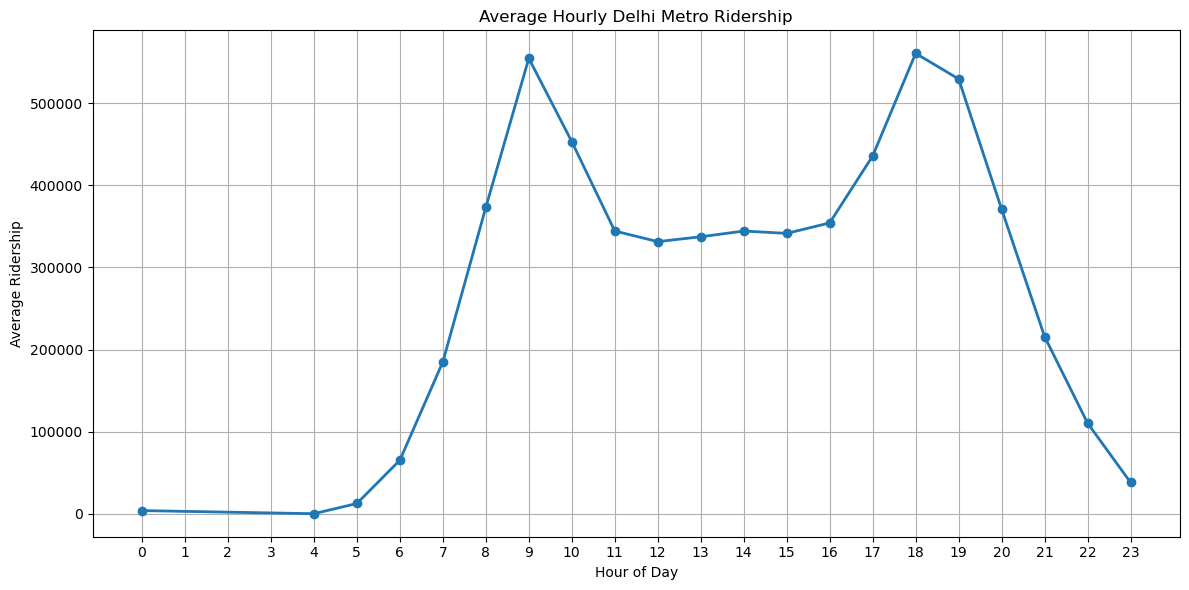

In [17]:
plt.plot(
    hourly_summary["hour"],
    hourly_summary["Average_Ridership"],
    marker="o",
    linewidth=2
)
plt.title("Average Hourly Delhi Metro Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

### Observations

- Ridership remains negligible between 00:00 and 04:00, corresponding to the Delhi Metro's non-operational hours.
- Passenger activity begins increasing after 04:00 as metro services commence.
- Ridership rises sharply between 07:00 and 09:00, indicating the morning commuting period.
- The morning peak occurs at approximately 09:00.
- Ridership decreases after the morning peak and remains relatively stable between 11:00 and 16:00.
- A second increase in ridership begins around 17:00.
- The evening peak occurs at approximately 18:00 and is slightly higher than the morning peak.
- Ridership declines steadily after 19:00 and decreases rapidly after 20:00 until the end of operational hours.
### Key Insights

- Delhi Metro ridership exhibits a clear bimodal distribution, with distinct morning and evening commuting peaks.
- The evening peak is slightly higher than the morning peak, suggesting stronger passenger movement during evening return journeys.
- Ridership remains relatively stable between the two peak periods, indicating sustained daytime travel beyond office commuting.
- Passenger demand is highly concentrated during operational commuting hours, making these periods the primary focus for future ridership forecasting and weather impact analysis.

# How much does each hour contribute to daily ridership

In [18]:
total_daily_ridership = hourly_summary["Average_Ridership"].sum()
total_daily_ridership

np.float64(5960451.9779005535)

In [19]:
hourly_summary["Percentage_Contribution"] = (
    hourly_summary["Average_Ridership"] /
    total_daily_ridership
) * 100

hourly_summary.head(24)

,hour,Average_Ridership,Percentage_Contribution
0,0,3910.44,6.56e-02
1,4,133.95,2.25e-03
2,5,12573.94,2.11e-01
3,6,65233.78,1.09e+00
4,7,184917.65,3.10e+00
5,8,373098.98,6.26e+00
6,9,554460.17,9.30e+00
7,10,453055.07,7.60e+00
8,11,344259.35,5.78e+00
9,12,331346.92,5.56e+00


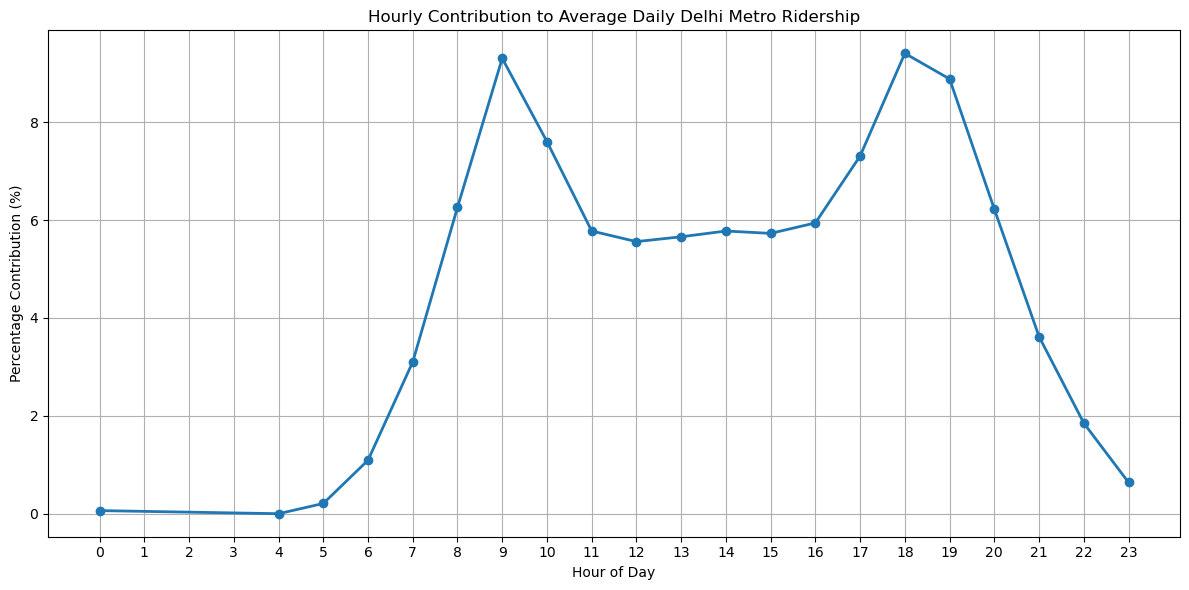

In [20]:
plt.plot(
    hourly_summary["hour"],
    hourly_summary["Percentage_Contribution"],
    marker="o",
    linewidth=2
)

plt.title("Hourly Contribution to Average Daily Delhi Metro Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Percentage Contribution (%)")
plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [21]:
hourly_summary.sort_values(
    by="Percentage_Contribution",
    ascending=False
).head(5)

,hour,Average_Ridership,Percentage_Contribution
15,18,560512.56,9.40
6,9,554460.17,9.30
16,19,529328.45,8.88
7,10,453055.07,7.60
14,17,435585.89,7.31


### Observations

- Passenger contribution remains negligible between 00:00 and 04:00 due to non-operational hours.
- Hourly contribution increases rapidly after 07:00, leading to the morning peak at 09:00 (9.30%).
- The highest hourly contribution occurs at 18:00, accounting for 9.40% of the average daily ridership.
- The top five contributing hours are 18:00, 09:00, 19:00, 10:00, and 17:00.
- Between 11:00 and 16:00, each hour consistently contributes approximately 5.5–6.0% of the average daily ridership.
- Hourly contribution declines steadily after 19:00 until the end of service hours.

### Key Insights

- Daily ridership is concentrated within a few peak commuting hours.
- The evening peak contributes slightly more to daily ridership than the morning peak.
- Midday ridership remains stable, indicating sustained travel demand beyond peak commuting periods.
- Peak hours should be prioritised for ridership forecasting and weather impact analysis.

In [22]:
# Display the top 5 hours contributing to average daily ridership

top5_contribution = (
    hourly_summary
    .sort_values(
        by="Percentage_Contribution",
        ascending=False
    )
    .head(5)
)

top5_contribution = (
    top5_contribution[
        ["hour", "Average_Ridership", "Percentage_Contribution"]
    ]
    .round({
        "Average_Ridership": 0,
        "Percentage_Contribution": 2
    })
)

top5_contribution

,hour,Average_Ridership,Percentage_Contribution
15,18,560513.0,9.40
6,9,554460.0,9.30
16,19,529328.0,8.88
7,10,453055.0,7.60
14,17,435586.0,7.31


# how does metro ridership change fro one hour to the next hour?
### Objective
- Determine the hourly increase or decrease in ridership to identify the periods with the most rapid changes in passenger demand.

In [23]:
# Calculate the hour-to-hour change in average ridership
hourly_change = hourly_summary.copy()

hourly_change["Ridership_Change"] = (
    hourly_change["Average_Ridership"].diff()
)

# Create interval labels (e.g., 07:00–08:00)
hourly_change["Interval"] = (
    (hourly_change["hour"] - 1).astype(int).astype(str).str.zfill(2)
    + ":00–"
    + hourly_change["hour"].astype(int).astype(str).str.zfill(2)
    + ":00"
)

# Remove the first row since it has no previous hour
hourly_change = hourly_change.iloc[1:].reset_index(drop=True)

hourly_change.head()

,hour,Average_Ridership,Percentage_Contribution,Ridership_Change,Interval
0,4,133.95,2.25e-03,-3776.49,03:00–04:00
1,5,12573.94,2.11e-01,12439.99,04:00–05:00
2,6,65233.78,1.09e+00,52659.85,05:00–06:00
3,7,184917.65,3.10e+00,119683.87,06:00–07:00
4,8,373098.98,6.26e+00,188181.33,07:00–08:00


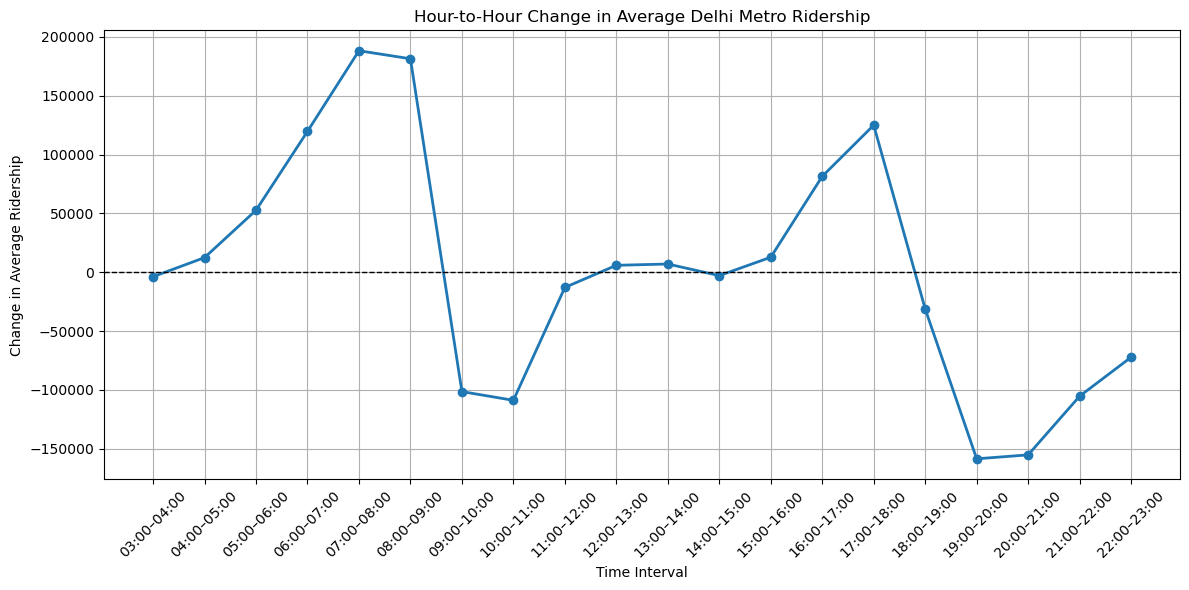

In [24]:
plt.plot(
    hourly_change["Interval"],
    hourly_change["Ridership_Change"],
    marker="o",
    linewidth=2
)

plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Hour-to-Hour Change in Average Delhi Metro Ridership")
plt.xlabel("Time Interval")
plt.ylabel("Change in Average Ridership")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [25]:
# Find the largest increase and decrease in ridership

largest_increase = (
    hourly_change
    .nlargest(1, "Ridership_Change")
    [["Interval", "Ridership_Change"]]
    .round({"Ridership_Change": 2})
)

largest_decrease = (
    hourly_change
    .nsmallest(1, "Ridership_Change")
    [["Interval", "Ridership_Change"]]
    .round({"Ridership_Change": 2})
)

print("Largest Increase")
display(largest_increase)

print("\nLargest Decrease")
display(largest_decrease)

Largest Increase


,Interval,Ridership_Change
4,07:00–08:00,188181.33



Largest Decrease


,Interval,Ridership_Change
16,19:00–20:00,-158500.44


### Observations

- Ridership increases continuously from 04:00–05:00 and reaches its fastest growth during **07:00–08:00**, with an increase of approximately **188,181** passengers.
- The largest decline occurs during **19:00–20:00**, with a decrease of approximately **158,500** passengers.
- A sharp decline is also observed immediately after the morning peak (09:00–11:00).
- Midday ridership changes remain relatively small, indicating stable passenger demand between peak periods.
- Ridership rises again between **16:00–18:00**, marking the onset of the evening peak.
### Key Insights

- Passenger demand changes most rapidly during the beginning and end of peak commuting periods.
- The morning rush develops more gradually, whereas the evening rush ends with a sharper decline.
- Stable hour-to-hour changes during midday indicate consistent off-peak travel demand.
- Hours exhibiting the largest changes are likely to be the most sensitive to external factors such as weather and should receive greater attention during forecasting.

# Calculate the average hourly Entry and Exit ridership


In [26]:
# Calculate the average hourly Entry and Exit ridership

hourly_entry_exit = (
    daily_hourly_total
    .groupby("hour")
    .agg(
        Average_Entry=("Entry", "mean"),
        Average_Exit=("Exit", "mean")
    )
    .reset_index()
)

hourly_entry_exit.head()

,hour,Average_Entry,Average_Exit
0,0,70.49,3839.95
1,4,109.55,24.40
2,5,11992.55,581.39
3,6,48618.29,16615.50
4,7,116682.67,68234.98


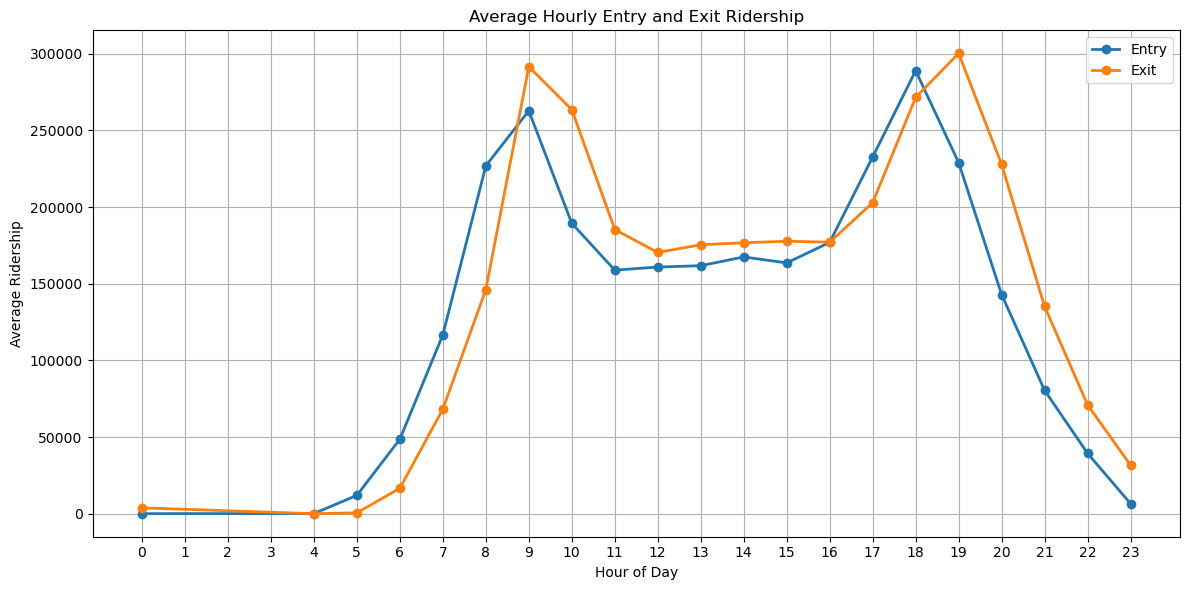

In [27]:
plt.plot(
    hourly_entry_exit["hour"],
    hourly_entry_exit["Average_Entry"],
    marker="o",
    linewidth=2,
    label="Entry"
)

plt.plot(
    hourly_entry_exit["hour"],
    hourly_entry_exit["Average_Exit"],
    marker="o",
    linewidth=2,
    label="Exit"
)

plt.title("Average Hourly Entry and Exit Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")

plt.xticks(range(24))

plt.legend()

plt.tight_layout()
plt.show()

In [28]:
peak_entry = (
    hourly_entry_exit
    .nlargest(1, "Average_Entry")
    [["hour", "Average_Entry"]]
    .round({"Average_Entry": 0})
)

peak_exit = (
    hourly_entry_exit
    .nlargest(1, "Average_Exit")
    [["hour", "Average_Exit"]]
    .round({"Average_Exit": 0})
)

print("Peak Entry Hour")
display(peak_entry)

print("\nPeak Exit Hour")
display(peak_exit)

Peak Entry Hour


,hour,Average_Entry
15,18,288989.0



Peak Exit Hour


,hour,Average_Exit
16,19,300291.0


### Observations

- Entry ridership peaks at **18:00** (288,989 passengers), while Exit ridership peaks at **19:00** (300,291 passengers).
- Entry ridership is higher than Exit ridership during the morning commute.
- Exit ridership dominates during the evening commute.
- Entry and Exit ridership are nearly equal around **16:00**.
- Both Entry and Exit follow a clear morning and evening peak pattern.

### Key Insights

- Morning travel is characterised by passenger entries, whereas evening travel is dominated by passenger exits.
- The one-hour lag between the Entry and Exit peaks reflects typical commuter movement across the metro network.
- The distinct temporal patterns indicate that Entry and Exit ridership should be modelled separately in subsequent forecasting analyses.

## What is the hourly difference between Entry and Exit ridership?

Calculate:

```
Entry - Exit
```

for every hour.

**Questions to Answer**

- Which hour has the largest imbalance?
- Does the morning differ from the evening?
- Is the imbalance consistent throughout the day?


In [29]:
# Calculate the hourly difference between Entry and Exit ridership

hourly_entry_exit["Entry_Exit_Difference"] = (
    hourly_entry_exit["Average_Entry"] -
    hourly_entry_exit["Average_Exit"]
)

hourly_entry_exit.head()

,hour,Average_Entry,Average_Exit,Entry_Exit_Difference
0,0,70.49,3839.95,-3769.46
1,4,109.55,24.40,85.15
2,5,11992.55,581.39,11411.17
3,6,48618.29,16615.50,32002.79
4,7,116682.67,68234.98,48447.70


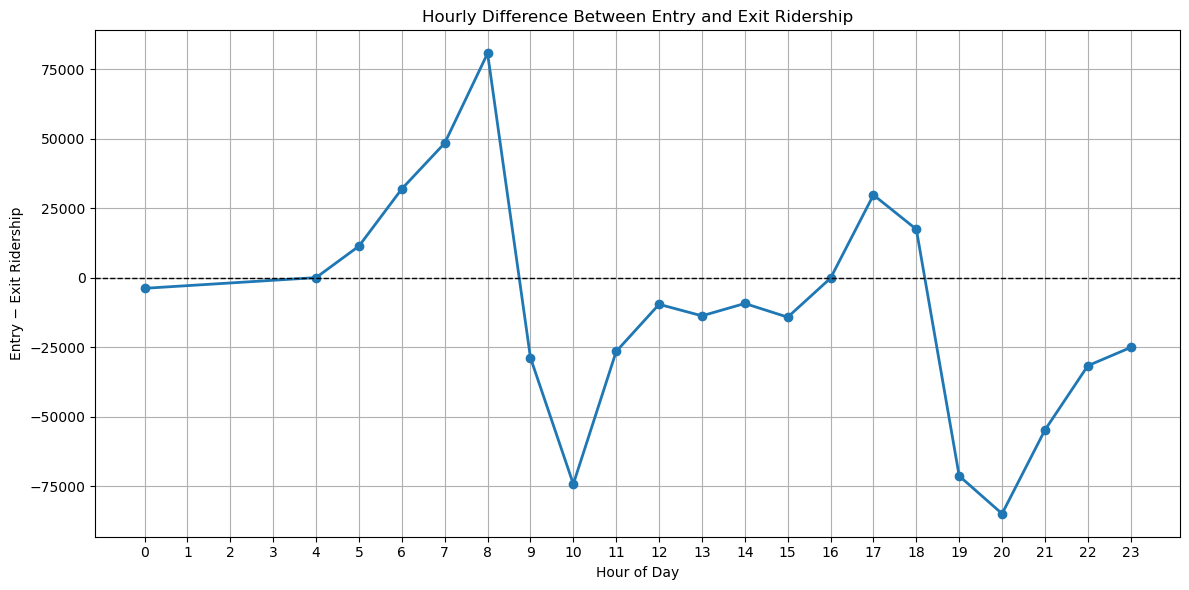

In [30]:
plt.plot(
    hourly_entry_exit["hour"],
    hourly_entry_exit["Entry_Exit_Difference"],
    marker="o",
    linewidth=2
)

# Reference line where Entry = Exit
plt.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Hourly Difference Between Entry and Exit Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Entry − Exit Ridership")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [31]:
largest_positive = (
    hourly_entry_exit
    .nlargest(1, "Entry_Exit_Difference")
    [["hour", "Entry_Exit_Difference"]]
    .round({"Entry_Exit_Difference": 0})
)

largest_negative = (
    hourly_entry_exit
    .nsmallest(1, "Entry_Exit_Difference")
    [["hour", "Entry_Exit_Difference"]]
    .round({"Entry_Exit_Difference": 0})
)

print("Largest Positive Difference (More Entries)")
display(largest_positive)

print("\nLargest Negative Difference (More Exits)")
display(largest_negative)

Largest Positive Difference (More Entries)


,hour,Entry_Exit_Difference
5,8,80747.0



Largest Negative Difference (More Exits)


,hour,Entry_Exit_Difference
17,20,-84839.0


### Observations

- The largest positive imbalance occurs at **08:00**, with approximately **80,747** more Entries than Exits.
- The largest negative imbalance occurs at **20:00**, with approximately **84,839** more Exits than Entries.
- Entry ridership exceeds Exit ridership during the morning hours, while Exit ridership dominates during the evening.
- The Entry–Exit difference approaches zero around **04:00** and **16:00**, indicating balanced passenger movement.
- The magnitude of the imbalance varies throughout the day, with the most pronounced differences occurring during peak commuting hours.

### Key Insights

- Morning and evening commuting periods exhibit opposite directional travel patterns, reflecting typical work-related travel behaviour.
- The greatest directional imbalance occurs during peak hours, indicating concentrated commuter movement.
- The varying Entry–Exit difference throughout the day highlights the importance of modelling directional ridership separately for forecasting and operational planning.

In [32]:
daily_hourly_total["businessday"].head(10)

0    2024-09-01
1    2024-09-01
2    2024-09-01
3    2024-09-01
4    2024-09-01
5    2024-09-01
6    2024-09-01
7    2024-09-01
8    2024-09-01
9    2024-09-01
Name: businessday, dtype: str

In [33]:
# Convert businessday column to datetime
daily_hourly_total["businessday"] = pd.to_datetime(
    daily_hourly_total["businessday"]
)
# Classify each date as Business Day or Non-Business Day
daily_hourly_total["Day_Type"] = (
    daily_hourly_total["businessday"]
    .dt.dayofweek
    .map({
        0: "Business Day",
        1: "Business Day",
        2: "Business Day",
        3: "Business Day",
        4: "Business Day",
        5: "Non-Business Day",
        6: "Non-Business Day"
    })
)

daily_hourly_total[["businessday", "Day_Type"]].head()

direction,businessday,Day_Type
0,2024-09-01,Non-Business Day
1,2024-09-01,Non-Business Day
2,2024-09-01,Non-Business Day
3,2024-09-01,Non-Business Day
4,2024-09-01,Non-Business Day


In [34]:
daily_hourly_total["Day_Type"].value_counts()

Day_Type
Business Day        2730
Non-Business Day    1071
Name: count, dtype: int64

In [35]:
daily_hourly_total[
    ["businessday", "Day_Type"]
].drop_duplicates().head(10)

direction,businessday,Day_Type
0,2024-09-01,Non-Business Day
21,2024-09-02,Business Day
42,2024-09-03,Business Day
63,2024-09-04,Business Day
84,2024-09-05,Business Day
105,2024-09-06,Business Day
126,2024-09-07,Non-Business Day
147,2024-09-08,Non-Business Day
168,2024-09-09,Business Day
189,2024-09-10,Business Day


In [36]:
daily_hourly_total.columns

Index(['businessday', 'month', 'hour', 'Entry', 'Exit', 'Total', 'Day_Type'], dtype='str', name='direction')

In [37]:
# Calculate average hourly ridership for Business and Non-Business Days

businessday_hourly = (
    daily_hourly_total
    .groupby(["Day_Type", "hour"])
    .agg(
        Average_Ridership=("Total", "mean")
    )
    .reset_index()
)

businessday_hourly.head()

,Day_Type,hour,Average_Ridership
0,Business Day,0,3586.24
1,Business Day,4,33.88
2,Business Day,5,12850.23
3,Business Day,6,70090.35
4,Business Day,7,209030.82


In [38]:
# Compare average total daily ridership

total_ridership = (
    daily_hourly_total
    .groupby("Day_Type")
    .agg(
        Average_Daily_Ridership=("Total", "mean")
    )
    .round(0)
)

total_ridership

,Average_Daily_Ridership
Day_Type,
Business Day,302272.0
Non-Business Day,236826.0


In [39]:
business = businessday_hourly[
    businessday_hourly["Day_Type"] == "Business Day"
]

non_business = businessday_hourly[
    businessday_hourly["Day_Type"] == "Non-Business Day"
]

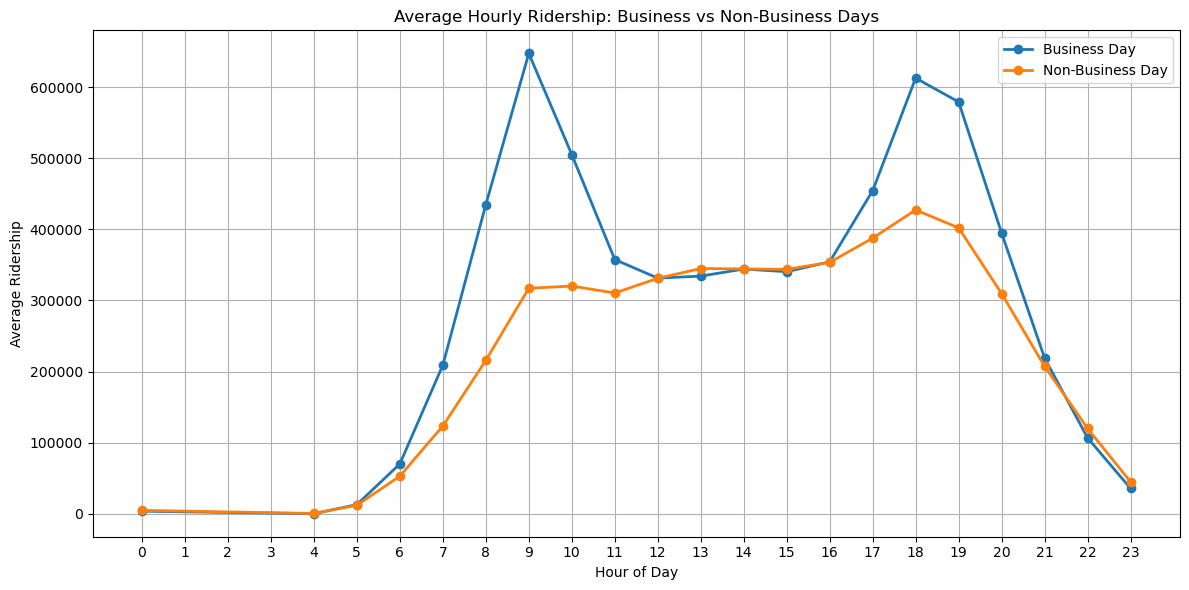

In [40]:
plt.plot(
    business["hour"],
    business["Average_Ridership"],
    marker="o",
    linewidth=2,
    label="Business Day"
)

plt.plot(
    non_business["hour"],
    non_business["Average_Ridership"],
    marker="o",
    linewidth=2,
    label="Non-Business Day"
)

plt.title("Average Hourly Ridership: Business vs Non-Business Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")

plt.xticks(range(24))
plt.legend()

plt.tight_layout()
plt.show()

In [41]:
business_peak = (
    business
    .nlargest(1, "Average_Ridership")
    [["hour", "Average_Ridership"]]
    .round({"Average_Ridership": 0})
)

non_business_peak = (
    non_business
    .nlargest(1, "Average_Ridership")
    [["hour", "Average_Ridership"]]
    .round({"Average_Ridership": 0})
)

print("Business Day Peak")
display(business_peak)

print("\nNon-Business Day Peak")
display(non_business_peak)

Business Day Peak


,hour,Average_Ridership
6,9,647565.0



Non-Business Day Peak


,hour,Average_Ridership
36,18,427323.0


In [42]:
daily_totals = (
    daily_hourly_total
    .groupby(["businessday", "Day_Type"])
    .agg(
        Daily_Ridership=("Total", "sum")
    )
    .reset_index()
)

average_daily_ridership = (
    daily_totals
    .groupby("Day_Type")
    .agg(
        Average_Daily_Ridership=("Daily_Ridership", "mean")
    )
    .round(0)
)

average_daily_ridership

,Average_Daily_Ridership
Day_Type,
Business Day,6.35e+06
Non-Business Day,4.97e+06


### Observations

- Average daily ridership decreases from **63.48 lakh** on Business Days to **49.73 lakh** on Non-Business Days.
- Business Days exhibit a sharp morning peak at **09:00** (6.48 lakh passengers), whereas the morning peak is considerably flatter on Non-Business Days.
- The evening peak persists on both day types, although it is lower on Non-Business Days, peaking at **18:00** (4.27 lakh passengers).
- Midday ridership remains relatively stable on Non-Business Days, indicating more evenly distributed travel demand.

### Key Insights

- Metro demand is significantly higher on Business Days, reflecting regular work and educational commuting patterns.
- The flatter morning peak on Non-Business Days suggests the absence of concentrated commuter travel.
- Non-Business Day travel is more evenly distributed throughout the day, whereas Business Day demand is concentrated during peak commuting hours.
```

### Question 8 
## How do Entry and Exit patterns differ between Business Days and Non-Business Days?

**Visualisation**

Four-line chart

Business Day
- Entry
- Exit

Non-Business Day
- Entry
- Exit

**Questions to Answer**

- Does commuting behaviour change?
- Are weekends more balanced?
- Which direction changes the most?

In [43]:
# Calculate average hourly Entry and Exit ridership by Day Type

businessday_entry_exit = (
    daily_hourly_total
    .groupby(["Day_Type", "hour"])
    .agg(
        Average_Entry=("Entry", "mean"),
        Average_Exit=("Exit", "mean")
    )
    .reset_index()
)

businessday_entry_exit.head()

,Day_Type,hour,Average_Entry,Average_Exit
0,Business Day,0,68.88,3517.36
1,Business Day,4,30.22,3.67
2,Business Day,5,12350.71,499.52
3,Business Day,6,52721.30,17369.05
4,Business Day,7,133803.61,75227.21


In [44]:
business = businessday_entry_exit[
    businessday_entry_exit["Day_Type"] == "Business Day"
]

non_business = businessday_entry_exit[
    businessday_entry_exit["Day_Type"] == "Non-Business Day"
]

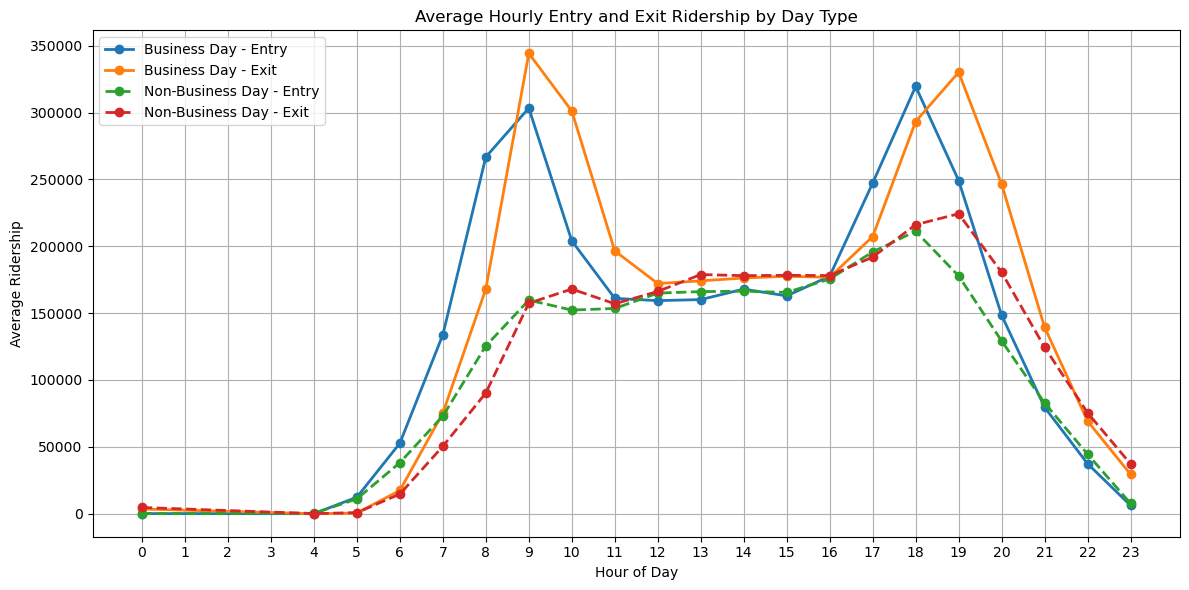

In [45]:
plt.plot(
    business["hour"],
    business["Average_Entry"],
    marker="o",
    linewidth=2,
    label="Business Day - Entry"
)

plt.plot(
    business["hour"],
    business["Average_Exit"],
    marker="o",
    linewidth=2,
    label="Business Day - Exit"
)

plt.plot(
    non_business["hour"],
    non_business["Average_Entry"],
    marker="o",
    linewidth=2,
    linestyle="--",
    label="Non-Business Day - Entry"
)

plt.plot(
    non_business["hour"],
    non_business["Average_Exit"],
    marker="o",
    linewidth=2,
    linestyle="--",
    label="Non-Business Day - Exit"
)

plt.title("Average Hourly Entry and Exit Ridership by Day Type")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")

plt.xticks(range(24))
plt.legend()

plt.tight_layout()
plt.show()

In [46]:
print("Business Day Peak Entry")
display(
    business.loc[business["Average_Entry"].idxmax()][["hour", "Average_Entry"]]
)

print("Business Day Peak Exit")
display(
    business.loc[business["Average_Exit"].idxmax()][["hour", "Average_Exit"]]
)

print("Non-Business Day Peak Entry")
display(
    non_business.loc[non_business["Average_Entry"].idxmax()][["hour", "Average_Entry"]]
)

print("Non-Business Day Peak Exit")
display(
    non_business.loc[non_business["Average_Exit"].idxmax()][["hour", "Average_Exit"]]
)

Business Day Peak Entry


hour                    18
Average_Entry    319500.91
Name: 15, dtype: object

Business Day Peak Exit


hour                    9
Average_Exit    344231.28
Name: 6, dtype: object

Non-Business Day Peak Entry


hour                    18
Average_Entry    211212.67
Name: 36, dtype: object

Non-Business Day Peak Exit


hour                   19
Average_Exit    224287.92
Name: 37, dtype: object

### Observations

- Business Days exhibit pronounced morning and evening peaks, while Non-Business Days show a flatter ridership profile throughout the day.
- Business Day Exit ridership peaks at **09:00** (3.44 lakh), whereas Business Day Entry ridership peaks at **18:00** (3.20 lakh).
- On Non-Business Days, both Entry and Exit volumes are lower and remain more closely aligned, with peaks occurring during the evening (18:00–19:00).
- The morning peak experiences the largest reduction on Non-Business Days, while midday ridership remains relatively stable.

### Key Insights

- Commuting behaviour differs substantially between Business and Non-Business Days, reflecting weekday work and educational travel patterns.
- Non-Business Day travel is more evenly distributed throughout the day, indicating a shift toward leisure and discretionary trips.
- The sharp decline in morning ridership on Non-Business Days suggests that weekday office and school commutes contribute most to peak metro demand.

In [47]:
print("Total Entries:", daily_hourly_total["Entry"].sum())
print("Total Exits :", daily_hourly_total["Exit"].sum())
print("Difference  :", daily_hourly_total["Entry"].sum() - daily_hourly_total["Exit"].sum())

Total Entries: 518847146
Total Exits : 559994662
Difference  : -41147516


# How does hourly ridership vary across different months?
Visualisation
Multi-line chart (one line per month)
September
October
November
December
January
February
Questions to Answer
Which month has the highest average ridership?
Does the morning peak change across months?
Does the evening peak change across months?
Are there seasonal trends before adding rainfall?


In [48]:
# Calculate average hourly ridership for each month

monthly_hourly = (
    daily_hourly_total
    .groupby(["month", "hour"])
    .agg(
        Average_Ridership=("Total", "mean")
    )
    .reset_index()
)

monthly_hourly.head()

,month,hour,Average_Ridership
0,December,0,3617.10
1,December,4,10.87
2,December,5,11471.68
3,December,6,60559.42
4,December,7,176327.58


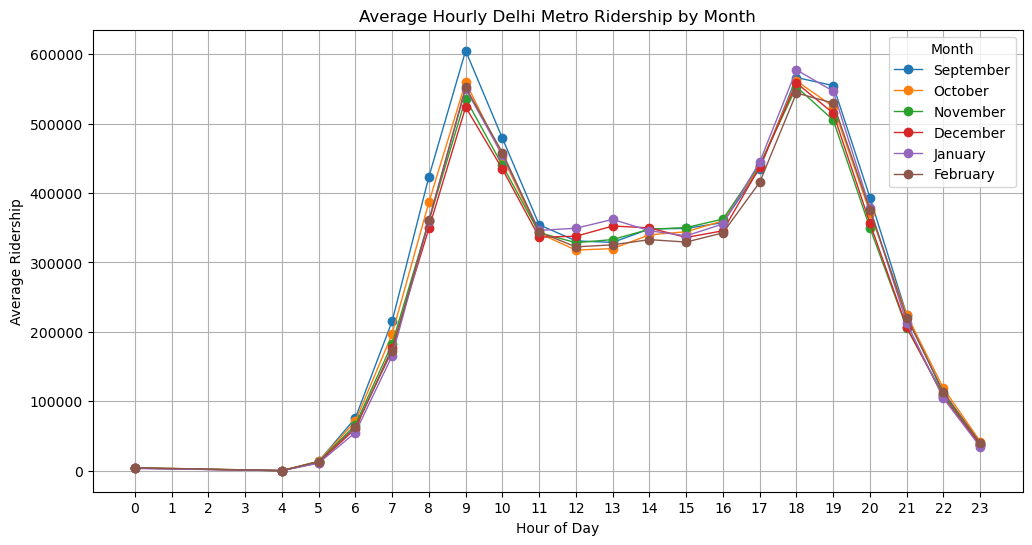

In [50]:
# Plot average hourly ridership by month

months_order = [
    "September",
    "October",
    "November",
    "December",
    "January",
    "February"
]

for month in months_order:
    temp = monthly_hourly[monthly_hourly["month"] == month]

    plt.plot(
        temp["hour"],
        temp["Average_Ridership"],
        marker="o",
        linewidth=1,
        label=month
    )

plt.title("Average Hourly Delhi Metro Ridership by Month")
plt.xlabel("Hour of Day")
plt.ylabel("Average Ridership")
plt.legend(title="Month")
plt.xticks(range(24))
plt.show()

In [51]:
# Peak hour for each month

monthly_peaks = (
    monthly_hourly
    .loc[
        monthly_hourly.groupby("month")["Average_Ridership"].idxmax()
    ]
    .sort_values("month")
)

monthly_peaks

,month,hour,Average_Ridership
15,December,18,558618.84
27,February,9,552479.11
57,January,18,577476.13
78,November,18,553125.77
99,October,18,561564.13
111,September,9,605074.87


### Observations & Key Insights

- Hourly ridership follows a consistent bimodal pattern across all months, with morning (09:00) and evening (18:00) peaks.
- September records the highest morning peak (~6.05 lakh), while January records the highest evening peak (~5.77 lakh).
- October, November and December show similar hourly demand patterns with only minor differences in ridership.
- Midday ridership (11:00–16:00) remains relatively stable across all months, averaging around 3.3–3.6 lakh passengers.
- Overall, monthly variations are modest, indicating that commuter travel behaviour remains consistent from September to February.

**Key Insight:** Ridership patterns are largely driven by daily commuting behaviour rather than monthly seasonality, providing a stable baseline for assessing the impact of rainfall in later analyses.

#How do morning and evening peaks compare across months?

###Instead of comparing the entire hourly curve again, we now focus only on the peak periods.

Objectives
Which month has the highest morning peak?
Which month has the highest evening peak?
Does the peak hour shift across months?
Does peak intensity vary by month?

In [53]:
# Extract morning (09:00) and evening (18:00) peak ridership

peak_comparison = (
    monthly_hourly[
        monthly_hourly["hour"].isin([9, 18])
    ]
    .pivot(
        index="month",
        columns="hour",
        values="Average_Ridership"
    )
    .rename(columns={
        9: "Morning Peak (09:00)",
        18: "Evening Peak (18:00)"
    })
    .reindex([
        "September",
        "October",
        "November",
        "December",
        "January",
        "February"
    ])
)

peak_comparison


hour,Morning Peak (09:00),Evening Peak (18:00)
month,,
September,605074.87,566451.07
October,559963.65,561564.13
November,536105.70,553125.77
December,523820.42,558618.84
January,550166.19,577476.13
February,552479.11,544215.61


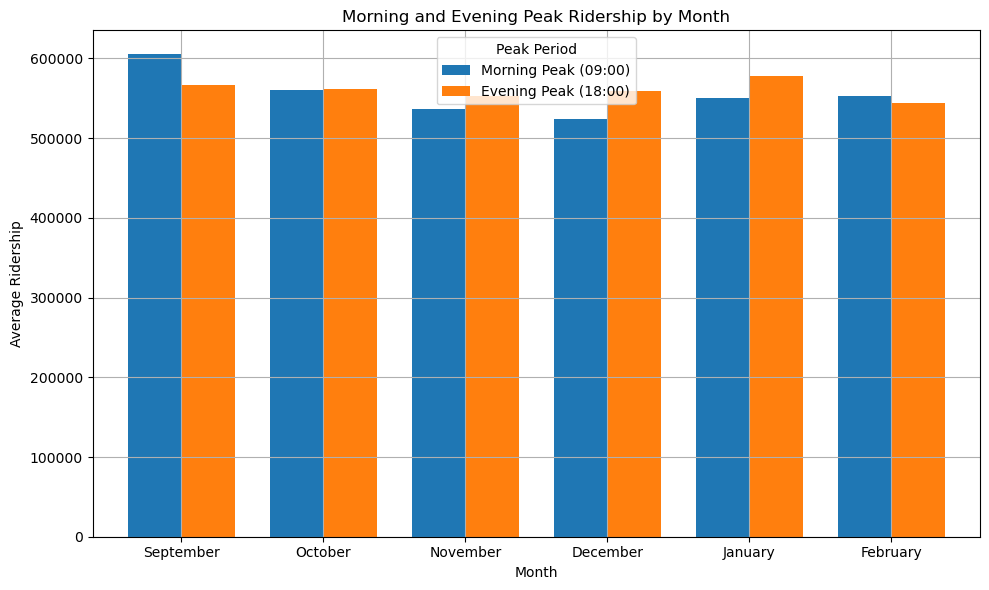

In [54]:
peak_comparison.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Morning and Evening Peak Ridership by Month")
plt.xlabel("Month")
plt.ylabel("Average Ridership")
plt.xticks(rotation=0)
plt.legend(title="Peak Period")

plt.tight_layout()
plt.show()

### Observations & Key Insights

- Morning peak ridership is highest in **September (6.05 lakh)**, while evening peak ridership is highest in **January (5.77 lakh)**.
- The morning peak gradually declines from September to December before recovering slightly in January and February.
- Evening peak ridership remains relatively stable across months, with only minor fluctuations.
- In **October, November, December and January**, the evening peak exceeds the morning peak, whereas **September and February** exhibit a stronger morning peak.

**Key Insight:** Peak-hour demand shows only modest monthly variation, indicating that commuter travel patterns remain stable across the study period. The consistent timing and magnitude of peak hours provide a reliable baseline for evaluating the impact of rainfall in subsequent forecasting analyses.
**Key Insight:** Peak-hour demand remains largely consistent across months, although the slightly higher evening peak during January may reflect seasonal influences such as winter travel behaviour. This relationship will be investigated further after integrating weather data.

Which hours exhibit the highest variability?

Instead of looking at the average ridership, we'll measure how much ridership fluctuates at each hour from day to day.
Why this matters

Suppose two hours both have an average ridership of 4 lakh.

Hour A varies between 3.95–4.05 lakh → very stable.
Hour B varies between 2.5–5.5 lakh → highly variable.

Although their averages are identical, Hour B is much harder to forecast.

In [55]:
hourly_variability = (
    daily_hourly_total
    .groupby("hour")
    .agg(
        Mean_Ridership=("Total", "mean"),
        Std_Ridership=("Total", "std")
    )
    .reset_index()
)

hourly_variability.head()

,hour,Mean_Ridership,Std_Ridership
0,0,3910.44,1065.59
1,4,133.95,881.93
2,5,12573.94,2764.79
3,6,65233.78,14242.94
4,7,184917.65,54659.76


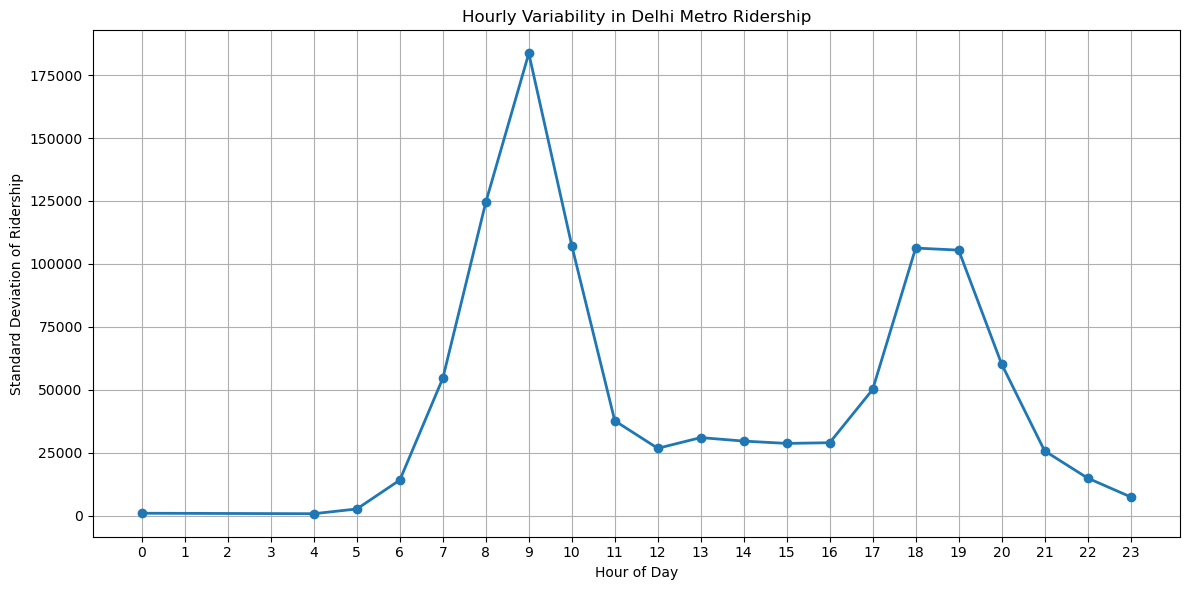

In [56]:
plt.plot(
    hourly_variability["hour"],
    hourly_variability["Std_Ridership"],
    marker="o",
    linewidth=2
)

plt.title("Hourly Variability in Delhi Metro Ridership")
plt.xlabel("Hour of Day")
plt.ylabel("Standard Deviation of Ridership")

plt.xticks(range(24))

plt.tight_layout()
plt.show()

In [57]:
most_variable = hourly_variability.loc[
    hourly_variability["Std_Ridership"].idxmax()
]

least_variable = hourly_variability.loc[
    hourly_variability["Std_Ridership"].idxmin()
]

print("Most Variable Hour")
display(most_variable)

print("\nLeast Variable Hour")
display(least_variable)

Most Variable Hour


hour                   9.00
Mean_Ridership    554460.17
Std_Ridership     183604.21
Name: 6, dtype: float64


Least Variable Hour


hour                4.00
Mean_Ridership    133.95
Std_Ridership     881.93
Name: 1, dtype: float64

### Observations & Key Insights

- Ridership variability is highest during the **09:00 morning peak**, with a standard deviation of **1.84 lakh** passengers, indicating the greatest day-to-day fluctuations.
- A secondary peak in variability occurs during the **18:00–19:00 evening commute**, although it is lower than the morning peak.
- Variability remains relatively low and stable during midday (11:00–16:00) and is minimal during non-operational and late-night hours.
- The least variable hour is **04:00**, with a standard deviation of only **882** passengers.

**Key Insight:** Peak commuting hours exhibit the greatest variability and are therefore likely to be the most challenging periods to forecast. These hours should receive greater attention during predictive modelling and weather impact analysis.

### Question 14 
## Which hours are most important for forecasting?

Identify the hours that simultaneously have:

- High passenger volume
- High variability

These hours will likely be the most valuable targets for predictive modelling.


In [58]:
forecast_priority = hourly_variability.copy()

forecast_priority.head()

,hour,Mean_Ridership,Std_Ridership
0,0,3910.44,1065.59
1,4,133.95,881.93
2,5,12573.94,2764.79
3,6,65233.78,14242.94
4,7,184917.65,54659.76


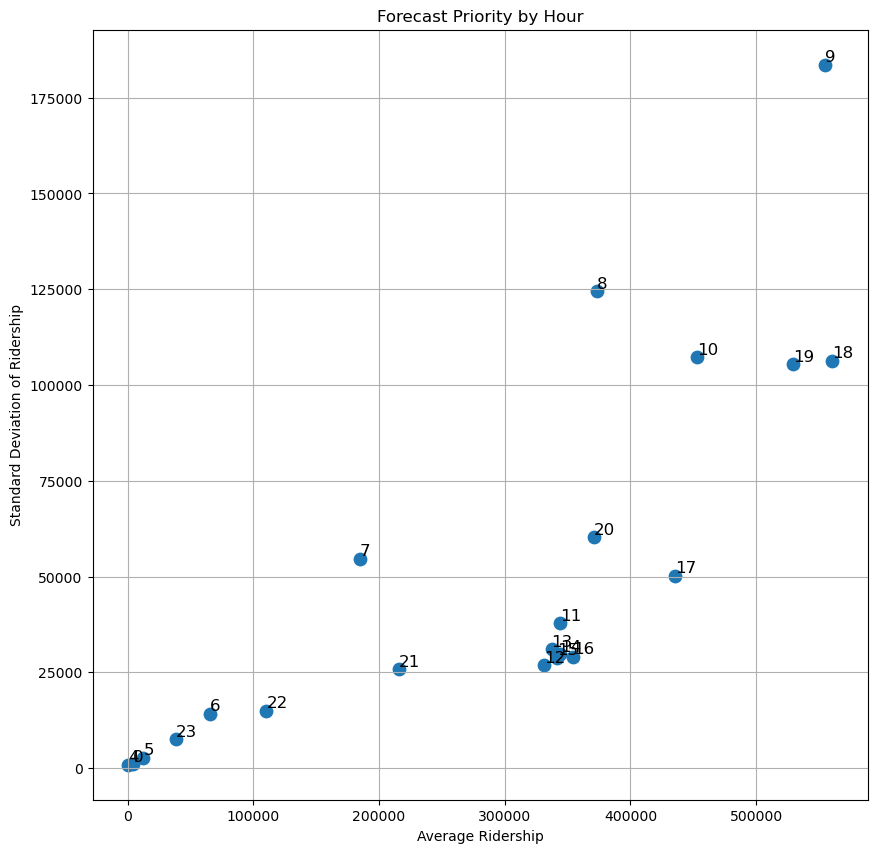

In [63]:
plt.figure(figsize=(10, 10))

plt.scatter(
    forecast_priority["Mean_Ridership"],
    forecast_priority["Std_Ridership"],
    s=80
)

# Label each point with the hour
for _, row in forecast_priority.iterrows():
    plt.text(
        row["Mean_Ridership"],
        row["Std_Ridership"],
        str(int(row["hour"])),
        fontsize=12,
        ha="left",
        va="bottom"
    )

plt.title("Forecast Priority by Hour")
plt.xlabel("Average Ridership")
plt.ylabel("Standard Deviation of Ridership")


plt.show()

In [60]:
forecast_priority["Forecast_Score"] = (
    forecast_priority["Mean_Ridership"] *
    forecast_priority["Std_Ridership"]
)

forecast_priority = forecast_priority.sort_values(
    by="Forecast_Score",
    ascending=False
)

forecast_priority[
    ["hour", "Mean_Ridership", "Std_Ridership", "Forecast_Score"]
].head(5)

,hour,Mean_Ridership,Std_Ridership,Forecast_Score
6,9,554460.17,183604.21,1.02e+11
15,18,560512.56,106317.85,5.96e+10
16,19,529328.45,105509.07,5.58e+10
7,10,453055.07,107270.22,4.86e+10
5,8,373098.98,124540.31,4.65e+10


### Observations & Key Insights

- **09:00** has the highest forecasting priority, combining the highest average ridership (**5.54 lakh**) with the greatest variability (**1.84 lakh**).
- The evening peak hours (**18:00–19:00**) also rank among the highest priority due to consistently high passenger demand and substantial variability.
- **08:00** and **10:00** exhibit high variability despite slightly lower average ridership, making them important transition periods around the morning peak.
- Non-peak and non-operational hours have both low ridership and low variability, indicating they are comparatively easier to forecast.

**Key Insight:** Forecasting efforts should primarily focus on the morning peak (**08:00–10:00**) and evening peak (**18:00–19:00**), where passenger volumes are highest and day-to-day fluctuations are greatest. Improving prediction accuracy during these periods would provide the greatest operational value.

# Time-Based EDA Summary

The time-based exploratory analysis provides a comprehensive understanding of Delhi Metro ridership patterns before incorporating weather variables.

### Key Findings

- Delhi Metro ridership exhibits a clear **bimodal commuting pattern**, with pronounced morning (09:00) and evening (18:00–19:00) peak periods.
- Approximately **19% of the average daily ridership** occurs during these two peak hours, highlighting their operational importance.
- Entry and Exit patterns follow expected commuter behaviour, with Entries dominating during the morning commute and Exits dominating during the evening commute.
- Business Days consistently record higher ridership than Non-Business Days, particularly during peak commuting hours, while weekends display flatter demand patterns.
- Monthly ridership patterns remain highly consistent from September to February, indicating limited seasonal variation in commuter behaviour during the study period.
- Peak-hour demand shows the greatest day-to-day variability, with **09:00** exhibiting the highest standard deviation, making it the most challenging hour to forecast.
- Forecast priority analysis identifies the **08:00–10:00 morning peak** and **18:00–19:00 evening peak** as the most critical periods for predictive modelling due to their combination of high passenger volumes and high variability.

### Conclusion

The time-based EDA establishes that Delhi Metro ridership is primarily governed by regular commuting behaviour, with stable temporal patterns across days and months. These findings provide a strong baseline for the next phase of the study, where weather variables such as rainfall will be integrated to evaluate their influence on metro ridership and improve forecasting performance.